In [534]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

!pip install datasets pillow matplotlib
!pip install --upgrade pillow
import PIL
print(PIL.__version__)

True
NVIDIA GeForce RTX 4090
12.2.0


In [535]:
import torch
print(torch.__version__)

2.12.0+cu130


In [536]:
import os

os.chdir("/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP")

print(os.getcwd())

/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP


In [537]:
import torch

state_dict = torch.load(
    "Weights/dino_pretrain.pth",
    map_location="cpu"
)

print(type(state_dict))
print("Loaded successfully")

<class 'dict'>
Loaded successfully


In [538]:
import sys
sys.path.append("AgriCLIP_alignment")



In [539]:
import sys
print(sys.executable)

/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/bin/python


In [540]:
import clip 
print ("clip OK")

clip OK


In [541]:
import open_clip 
print ("OK")

OK


In [542]:
import os

for root, dirs, files in os.walk("/home/zahranadeem"):
    if "dino_pretrain.pth" in files:
        print(os.path.join(root, "dino_pretrain.pth"))
        
        

print(os.getcwd())
print(os.listdir())

/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/dino_pretrain.pth
/home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
['README.md', 'images', '.gitignore', 'open_clip', 'dino', 'AgriCLIP_alignment', 'requirements.txt', 'Weights', 'Dataset', '.git']


In [543]:
import torch
import torch.nn as nn 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
projection_bridge = nn.Linear(384, 2048).to(device)

# Optional: Initialize with identity/uniform distribution to keep it stable
nn.init.eye_(projection_bridge.weight[:384, :384]) 

model = torch.hub.load(
    'facebookresearch/dino:main',
    'dino_resnet50',
    pretrained=True
)

model.load_state_dict(
    torch.load(
        "/home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth",
        map_location='cpu'
    )
)

model = model.to(device)
model.eval()

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


OutOfMemoryError: CUDA out of memory. Tried to allocate 2.00 MiB. GPU 0 has a total capacity of 23.52 GiB of which 19.88 MiB is free. Including non-PyTorch memory, this process has 23.05 GiB memory in use. Of the allocated memory 22.09 GiB is allocated by PyTorch, and 513.17 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
import sys
sys.path.append("/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment")

In [ ]:
from LinearAligner import LinearAligner

aligner = LinearAligner()

aligner.load_W(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/Aligned_Models/Agri_Dino_aligner_DPT_CPT.pth"
)

print("Aligner loaded")

Aligner loaded


In [ ]:
from TextToConcept import TextToConcept

print("TextToConcept imported")

TextToConcept imported


In [ ]:
from TextToConcept import TextToConcept





def forward_features(x):
    

    return model(x)

    
    #features = model(x)
    #return model(x)
    #return model.forward_features(x)

    #return features


model.forward_features = forward_features
text_to_concept = TextToConcept(model, 'Dino')

text_to_concept.load_linear_aligner(
    "/home/zahranadeem/AgriCLIP/Weights/Aligned_Models/Agri_Dino_aligner_DDEF_CDEF.pth"
)
print("AgriCLIP loaded")

AgriCLIP loaded


In [ ]:
#First we use concepts as they are broader and not species names

concepts = [
    "plant",
    "leaf",
    "crop",
    "weed",
    "soil",
    "grass"
]

In [ ]:
#Building zero shot classifier 

classifier = text_to_concept.get_zero_shot_classifier(
    concepts,
    prompts=["a photo of {}"]
)

print("Classifier ready")

Classifier ready


In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "simonMadec/VegAnn",
    cache_dir="/home/zahranadeem/.cache/huggingface"
)

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})


In [ ]:
subset = dataset["train"].select(range(100))

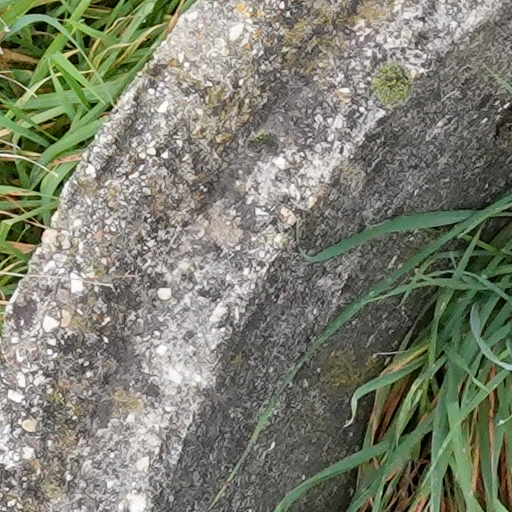

Species: Mix


In [ ]:
#Loading 1 vegann image
sample = subset[0]

image = sample["image"]

display(image)

print("Species:", sample["Species"])

In [ ]:
#Converting Image to Tensor
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

"""transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])"""

img_tensor = transform(image).unsqueeze(0)


In [ ]:
print(next(model.parameters()).device)

cuda:0


In [ ]:
print(img_tensor.device)

cpu


In [ ]:
#Move image to gpu 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

img_tensor = img_tensor.to(device)


In [ ]:
with torch.no_grad():
    feats = model(img_tensor)

print(feats.shape)

torch.Size([1, 2048])


In [ ]:
#Running AgriCLIP Prediction 
import torch

with torch.no_grad():
    logits = species_classifier(img_tensor.to(device))

print(logits)

tensor([[0.2674, 0.2404, 0.2681, 0.2265, 0.2669, 0.2486, 0.2494, 0.2873, 0.2556,
         0.2683, 0.2544, 0.2429, 0.2669, 0.2622, 0.2646, 0.2496, 0.2222, 0.2317,
         0.2515, 0.2363, 0.2344, 0.2685, 0.2541, 0.2254, 0.2852, 0.2469, 0.2412]],
       device='cuda:0')


In [ ]:
scores = logits.squeeze().cpu().numpy()

for concept, score in zip(concepts, scores):
    print(f"{concept}: {score:.4f}")
    
pred_idx = scores.argmax()

print("\n" + "="*40)
print("Prediction:", species_list_clean[pred_idx])
print("="*40)


plant: 0.2674
leaf: 0.2404
crop: 0.2681
weed: 0.2265
soil: 0.2669
grass: 0.2486

Prediction: mix


In [ ]:
species_list = sorted(
    list(set(dataset["train"]["Species"]))
)

# Force lowercase and clean typos (e.g., "Tabacco" -> "tobacco")
species_list_clean = [s.lower().replace("tabacco", "tobacco").replace("_", " ") for s in species_list]

species_classifier = text_to_concept.get_zero_shot_classifier(
    species_list_clean,
    prompts=["a photo of {}"]
)


print("Number of species:", len(species_list))
print(species_list)

Number of species: 27
['Alfalfa', 'Barley', 'Bean', 'Cabbage', 'Faba beans', 'Grassland', 'Maize', 'Mix', 'Mustard', 'Na', 'Oat', 'Onion', 'Pea', 'Pepper', 'Potato', 'Radish', 'Rapeseed', 'Raspberry', 'Rice', 'Sorghum', 'Sorrel', 'Soybean', 'Sugarbeet', 'Sunflower', 'Tabacco', 'Vetch', 'Wheat']


In [ ]:
species_classifier = text_to_concept.get_zero_shot_classifier(
    species_list,
    prompts=["a photo of {}"]
)

print("Species classifier ready")

Species classifier ready


Ground Truth: Rice


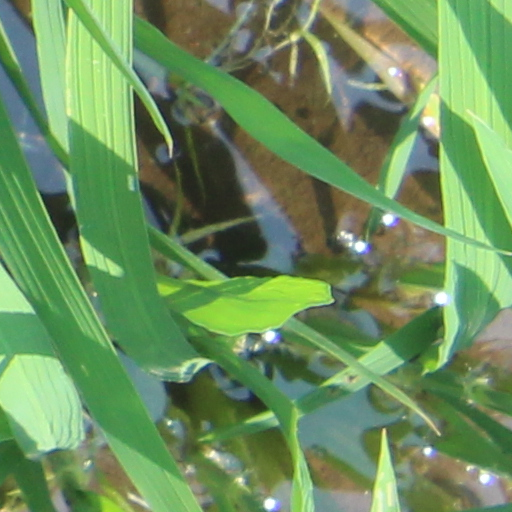

In [ ]:
sample = dataset["train"][2000]

print("Ground Truth:", sample["Species"])

image = sample["image"]

display(image)

In [ ]:
img_tensor = transform(image).unsqueeze(0).to(device)

In [ ]:
print(model.forward_features)

<function forward_features at 0x70095d150310>


In [ ]:
with torch.no_grad():
    logits = species_classifier(img_tensor)

scores = logits.squeeze().cpu().numpy()

In [ ]:
import numpy as np

top5_idx = np.argsort(scores)[-5:][::-1]

print("Ground Truth:", sample["Species"])
print()

for rank, idx in enumerate(top5_idx, start=1):
    print(
        f"{rank}. {species_list[idx]}  ({scores[idx]:.4f})"
    )

Ground Truth: Rice

1. Tabacco  (0.2733)
2. Sorrel  (0.2686)
3. Sugarbeet  (0.2649)
4. Maize  (0.2645)
5. Faba beans  (0.2638)


In [ ]:
import random
import numpy as np

correct_top1 = 0
correct_top5 = 0

indices = random.sample(range(len(dataset["train"])), 100)

for idx in indices:

    sample = dataset["train"][idx]

    image = sample["image"]
    gt = sample["Species"]

    img_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = species_classifier(img_tensor)

    scores = logits.squeeze().cpu().numpy()

    top5 = np.argsort(scores)[-5:][::-1]

    pred1 = species_list[top5[0]]

    if pred1 == gt:
        correct_top1 += 1

    if gt in [species_list[i] for i in top5]:
        correct_top5 += 1

print("Top1 Accuracy:", correct_top1/100)
print("Top5 Accuracy:", correct_top5/100)



OutOfMemoryError: CUDA out of memory. Tried to allocate 2.00 MiB. GPU 0 has a total capacity of 23.52 GiB of which 19.88 MiB is free. Including non-PyTorch memory, this process has 23.05 GiB memory in use. Of the allocated memory 22.09 GiB is allocated by PyTorch, and 513.19 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
prompt_templates = [
    "a photo of {}",
    "an agricultural image of {}",
    "a field image of {}",
    "a crop field containing {}",
    "a close-up image of {} crop"
]

In [ ]:
import random

random.seed(42)

test_indices = random.sample(
    range(len(dataset["train"])),
    10
)

print(test_indices)

[2619, 456, 102, 3037, 1126, 1003, 914, 571, 3016, 419]


In [ ]:
import numpy as np
import torch

for prompt in prompt_templates:

    print("\n" + "="*60)
    print("PROMPT:", prompt)
    print("="*60)

    species_classifier = text_to_concept.get_zero_shot_classifier(
        species_list,
        prompts=[prompt]
    )

    correct_top1 = 0
    correct_top5 = 0

    for idx in test_indices:

        sample = dataset["train"][idx]

        image = sample["image"]
        gt = sample["Species"]

        img_tensor = transform(image).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = species_classifier(img_tensor)

        scores = logits.squeeze().cpu().numpy()

        top5_idx = np.argsort(scores)[-5:][::-1]

        pred1 = species_list[top5_idx[0]]

        top5_species = [
            species_list[i]
            for i in top5_idx
        ]

        if pred1 == gt:
            correct_top1 += 1

        if gt in top5_species:
            correct_top5 += 1

    print(
        f"Top1 Accuracy: {correct_top1/10:.2f}"
    )

    print(
        f"Top5 Accuracy: {correct_top5/10:.2f}"
    )


PROMPT: a photo of {}
Top1 Accuracy: 0.00
Top5 Accuracy: 0.10

PROMPT: an agricultural image of {}
Top1 Accuracy: 0.00
Top5 Accuracy: 0.10

PROMPT: a field image of {}
Top1 Accuracy: 0.00
Top5 Accuracy: 0.10

PROMPT: a crop field containing {}
Top1 Accuracy: 0.00
Top5 Accuracy: 0.10

PROMPT: a close-up image of {} crop


OutOfMemoryError: CUDA out of memory. Tried to allocate 2.00 MiB. GPU 0 has a total capacity of 23.52 GiB of which 19.88 MiB is free. Including non-PyTorch memory, this process has 23.05 GiB memory in use. Of the allocated memory 22.09 GiB is allocated by PyTorch, and 513.19 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
concepts = [
    "plant",
    "leaf",
    "stem",
    "flower",
    "fruit",
    "weed",
    "grass",
    "soil",
    "bare soil",
    "agricultural machinery",
    "sky",
    "tree",
    "crop row",
    "dense vegetation",
    "dry vegetation"
]

In [ ]:
concept_classifier = text_to_concept.get_zero_shot_classifier(
    concepts,
    prompts=["an agricultural image of {}"]
)

print("Concept classifier ready")

Concept classifier ready


Species: Mix


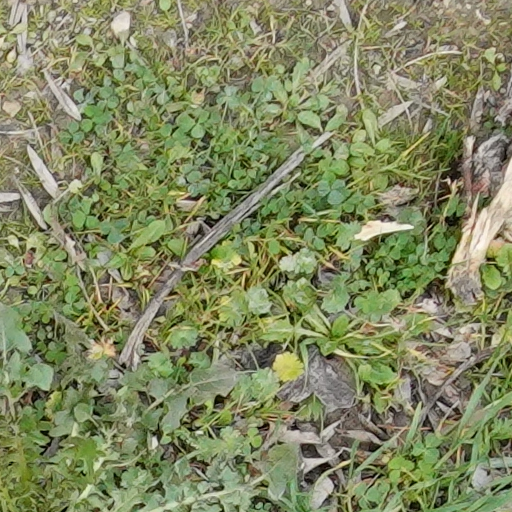

In [ ]:
sample = dataset["train"][10]

print("Species:", sample["Species"])

image = sample["image"]

display(image)

In [ ]:
img_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    logits = concept_classifier(img_tensor)

scores = logits.squeeze().cpu().numpy()

In [ ]:
import numpy as np

top5_idx = np.argsort(scores)[-5:][::-1]

print("Species:", sample["Species"])
print()

for rank, idx in enumerate(top5_idx, start=1):
    print(
        f"{rank}. {concepts[idx]} ({scores[idx]:.4f})"
    )

Species: Mix

1. stem (0.2524)
2. plant (0.2459)
3. leaf (0.2436)
4. bare soil (0.2410)
5. soil (0.2385)


In [ ]:
from collections import Counter

concept_counter = Counter()

In [ ]:
import random

random.seed(42)

test_indices = random.sample(
    range(len(dataset["train"])),
    100
)

In [ ]:
for idx in indices:


    sample = dataset["train"][idx]

    image = sample["image"]


    img_tensor = transform(image)

    img_tensor = img_tensor.unsqueeze(0).to(device)



    with torch.no_grad():

        logits = concept_classifier(img_tensor)



    scores = logits.squeeze().cpu().numpy()



    top3 = np.argsort(scores)[-3:][::-1]



    for i in top3:

        concept_counter[concepts[i]] += 1

In [ ]:
print("Concept Frequencies\n")


for k,v in concept_counter.most_common():

    print(k,v)

Concept Frequencies

plant 100
stem 99
leaf 88
dry vegetation 12
bare soil 1


In [ ]:
for idx in test_indices:

    sample = dataset["train"][idx]

    image = sample["image"]

    img_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = concept_classifier(img_tensor)

    scores = logits.squeeze().cpu().numpy()

    top3_idx = np.argsort(scores)[-3:][::-1]

    print("="*60)
    print("Species:", sample["Species"])

    print("Top Concepts:")

    for i in top3_idx:
        print(
            f"   {concepts[i]} ({scores[i]:.4f})"
        )

    print()

Species: Wheat
Top Concepts:
   stem (0.2530)
   plant (0.2488)
   leaf (0.2448)

Species: Sunflower
Top Concepts:
   stem (0.2577)
   plant (0.2553)
   leaf (0.2553)

Species: Mix
Top Concepts:
   stem (0.2552)
   plant (0.2541)
   leaf (0.2536)

Species: Sorghum
Top Concepts:
   stem (0.2448)
   plant (0.2444)
   leaf (0.2390)

Species: Wheat
Top Concepts:
   stem (0.2481)
   plant (0.2475)
   leaf (0.2430)

Species: Grassland
Top Concepts:
   stem (0.2500)
   plant (0.2458)
   leaf (0.2425)

Species: Wheat
Top Concepts:
   leaf (0.2847)
   stem (0.2792)
   plant (0.2777)

Species: Wheat
Top Concepts:
   stem (0.2448)
   leaf (0.2442)
   plant (0.2423)

Species: Na
Top Concepts:
   stem (0.2445)
   plant (0.2400)
   soil (0.2390)

Species: Wheat
Top Concepts:
   stem (0.2486)
   plant (0.2423)
   leaf (0.2402)



In [ ]:

#RETRIEVEL experiment
query = 'plant'

In [ ]:
vec = text_to_concept.encode_text(

            [[query]]

)


print(vec.shape)

torch.Size([1, 512])


In [ ]:
similarities = [] 
for i in range(100):


    sample = dataset["train"][i]



    image = sample["image"]


    img_tensor = transform(image)

    img_tensor = img_tensor.unsqueeze(0).to(device)



    with torch.no_grad():

        feats = model.forward_features(

                        img_tensor

                )


        feats = feats.flatten(1)



        aligned = text_to_concept.linear_aligner.get_aligned_representation(

                        feats
                    )


        aligned /= aligned.norm(

                        dim=-1,
                        keepdim=True
                        )



        sim = aligned @ vec.T




    similarities.append(


            sim.item()

    )

In [ ]:
best = np.argsort(similarities)[::-1]


top5 = best[:5]


print(top5)

[19 88  1 68 50]


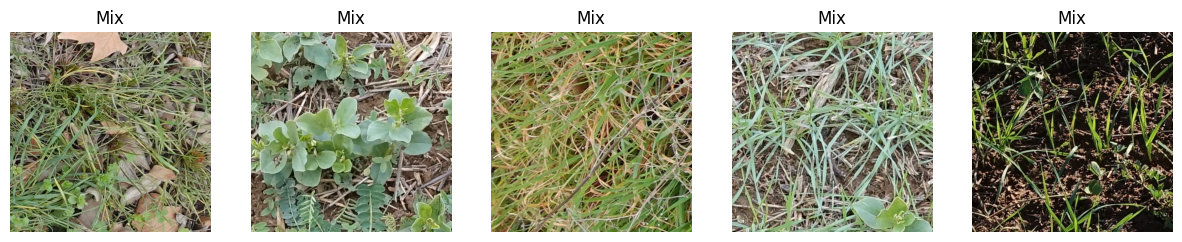

In [ ]:
import matplotlib.pyplot as plt



fig,axs = plt.subplots(

                1,
                5,

                figsize=(15,4)
                )




for j,idx in enumerate(top5):


    sample = dataset["train"][idx]



    axs[j].imshow(

            sample["image"]

            )


    axs[j].axis("off")


    axs[j].set_title(

            sample["Species"]

            )



plt.show()